---
title: "Week 5 Homework"
subtitle: DS 2023 | Communicating with Data
---

## Overview

This homework explores word frequency and part of speech (POS) across a combined corpus of novels by Jane Austen and Herman Melville. 

## The data set

The dataset is a vocabulary table built from the combined novels of Jane Austen and Herman Melville.

| Column | Description |
|---|---|
| `term_str` | The unique word form, including only unigrams (single words). Often called a **term** or a **type**. All terms are lower-case, including proper nouns. |
| `n` | Number of times the term appears across the corpus. This is the number of **tokens** in the corpus associated with the type. Also known as "term frequency" or **TF**. |
| `p` | The relative frequency of the term in the corpus the word accounts for. This is an estimate of the marginal **probability** of the term.|
| `n_chars` | Number of characters in the word. Also know as term length. |
| `max_pos_group` | Most common part-of-speech category group assigned to this word in the corpus. Codes based on the Penn Treebank system. See below. |
| `stop` | Whether the word is a "stop word", i.e. a high-frequency word that may be excluded from various NLP tasks. $1$ if the word is a stop word, $0$ otherwise. |

**About parts of speech**

Each word was tagged by an NLP tagger and assigned a part-of-speech category drawn from the [Penn Treebank](https://www.ling.upenn.edu/courses/Fall_2003/ling001/penn_treebank_pos.html).

The system used here is a truncated version of the Penn system that groups POS tags into two-letter codes.

Here are the codes that compose the domain of the `max_pos_group` variable: 

|Code | Meaning|
|-----|--------|
|NN| Noun| 
|VB| Verb| 
|JJ| Adjective| 
|RB| Adverb| 
|CD| Cardinal number| 
|IN| Preposition| 
|PR| Pronoun| 
|DT| Determiner| 
|FW| Foreign word| 
|MD| Modal  | 
|CC| Coordinating conjunction| 
|WR| Wh-adverb| 
|PO| Possessive ending| 
|PD| Predeterminer| 
|RP| Particle| 
|WP| Wh-pronoun| 
|WD| Wh-determiner| 
|EX| Existential there| 
|TO| the word _to_ | 

Note that, as a general rule, the **first four** categories identify words that do **semantic work**, while the rest of the words do **grammatical** works.

By semantic work, we mean that the words are **content** words used to reference things in the world, whereas grammatical work refers to words that **connect** words into meaningful sentences.

## Tasks

### Task 0: Load data

0 points 

**Load and inspect the data.**

The data URL is here: 

```
https://virginia.box.com/shared/static/ltrh4n9a2eihpo91tjs3ys53hh4lv0lo.csv
```

### Task 1: Term frequency TF

1 point

1. How many unique word forms (`term_str`) are in the vocabulary?
2. What is the most frequent value of `term_str`?
3. How often does it appear, expressed as relative frequency rounded to $2$ decimals?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://virginia.box.com/shared/static/ltrh4n9a2eihpo91tjs3ys53hh4lv0lo.csv"
vocab = pd.read_csv(url)

vocab.head()

,term_str,n,p,n_chars,max_pos_group,stop
0,0,2,9.713651e-07,1,CD,0
1,1,23,1.117070e-05,1,CD,0
2,10,6,2.914095e-06,2,CD,0
3,100,2,9.713651e-07,3,CD,0
4,1000,2,9.713651e-07,4,CD,0


In [8]:
len(vocab)

40283

In [3]:
vocab['n'].idxmax()

35232

In [11]:
round(vocab.loc[vocab['n'].idxmax(), 'p'], 2)

np.float64(0.05)

**Answers:**
1. 40283
2. 35232
3. 0.05

### Task 2: Histogram of TF 

1 point

Plot a histogram of `n` using $50$ bins.

What does the plot show?

Note that the resulting plot shows a **frequency of frequencies** &mdash; how many times frequency value occurs.

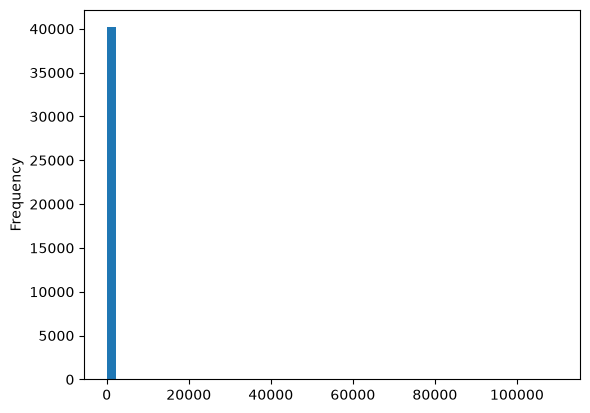

In [27]:
n_bins = 50
vocab['n'].plot.hist(bins=n_bins)

plt.show()

**Answer:**
The plot shows a strongly right-skewed distribution because the range of the x-axis stretches far right. 

### Task 3: Box plot of log TF

3 points

Now create a histogram and a box plot of the $log_{10}$ value of `n`.

To do this, first create a column `log_n` that is created by `np.log10(vocab['n'])`.

Then plot the new column.

Make the box plot horizontal.

Use $50$ bins for the histogram.

Place the two plots in a single figure with two axes objects in a single columns. 

Have the two plots share the x axis.

Hint: Use `fig, ax = subplots()` with the appropriate arguments.

**Question:** What do these two plots together show that the first plot does not?

In [28]:
vocab['log_n']=np.log10(vocab['n'])

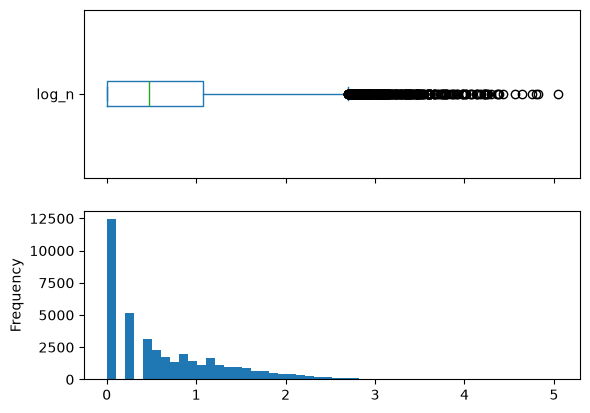

In [38]:
fig, (ax_box, ax_hist) = plt.subplots(2, 1, sharex=True)

vocab['log_n'].plot.hist(bins=50)

vocab['log_n'].plot.box(ax=ax_box, vert=False)

plt.show()

**Answer:**

These two plots show the strongly right-skewed distribution more clearly than the first plot. They also provide more information about the dataset's statistics such as possible outliers, median, and IQR.

### Task 4: Frequency of POS

1 point

Using the histogram above as your guide, choose a log value somewhere in the _middle_ of the outlier points.

Call this value `thresh`.

Using this value, get the top 4 POS groups for terms with values above that threshhold.

Call the resulting list of these POS codes `group_a`.

Also get the top 4 POS groups for terms with values below that threshhold.

Call the resulting list of these POS codes `group_b`.

**Question:** Consulting the POS code defintions and notes above, characterize the difference between the two groups.

In [43]:
thresh = 4

group_a = (
    vocab[vocab['log_n'] > thresh]['max_pos_group']
    .value_counts()
    .head(4)
    .index.tolist()
)

group_b = (
    vocab[vocab['log_n'] < thresh]['max_pos_group']
    .value_counts()
    .head(4)
    .index.tolist()
)

group_a, group_b

(['IN', 'PR', 'VB', 'DT'], ['NN', 'VB', 'JJ', 'RB'])

**Answer:**
The POS that appear above the threshold are Preposition, Pronoun, Verb, and Determiner.

The POS that appear below the threshold are Noun, Verb, Adjective, and Adverb.

I notice the difference between the two groups are that the POS that appear above the threshold are words related to grammatical structure to connect ideas, while the POS that appear below the threshold tend to be semantic and refer to the meaning and ideas themselves.

### Task 5: Question

1 point

**Question:** Do the most frequent terms belong to the most frequenct POS groups?

In [46]:
vocab.sort_values('n',ascending=False).head(), group_a

(      term_str       n         p  n_chars max_pos_group  stop     log_n
 35232      the  109921  0.053387        3            DT     1  5.041081
 24259       of   65525  0.031824        2            IN     1  4.816407
 1442       and   62954  0.030576        3            CC     1  4.799023
 35716       to   56271  0.027330        2            TO     1  4.750285
 201          a   44174  0.021455        1            DT     1  4.645167,
 ['IN', 'PR', 'VB', 'DT'])

**Answer:**

Not all of the most frequent terms belong to the most frequent POS groups.

### Task 6

3 points

Create a wide table showing projecting POS groups onto axis 1 (the columns) of the dataframe and `log_n` populating its cells (the values).

Include only the set of POS groups that are represents in `group_a` and `group_b`.

Hint: Use `list(set(group_a + group_b))` to get the subset of columns in the wide table.

Plot the wide table as a KDE plot setting the bandwidth to $1$.

Also, set linewidth (`lw`) to $3$ so you can read the legend more clearly.

Use a figure size of $10$ by $5$.

You should see two groups of curves, based on their maxima (peaks). One group, on the left, peaks just above $0$ while the other group, on the right, peaks at just below $4$.

**Questions:** 

1. What POS group has the highest peak in the right-hand group?
2. What POS group has the lowest peak in the left-hand group?
3. Does the answer to the previous question call into question general rule regarding the relationship between frequency on the kind of "work" a word does? You may look up the meaning of the POS group to help you answer this question. Explain your answer in a sentence.

In [48]:
vocab.head(1)

,term_str,n,p,n_chars,max_pos_group,stop,log_n
0,0,2,9.713651e-07,1,CD,0,0.30103


In [63]:
vocab_wide_df = vocab.pivot(columns='max_pos_group', values='log_n')[list(set(group_a + group_b))]

vocab_wide_df

max_pos_group,VB,DT,JJ,RB,PR,NN,IN
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
40278,NaN,NaN,NaN,NaN,NaN,0.00000,NaN
40279,NaN,NaN,NaN,NaN,NaN,0.00000,NaN
40280,NaN,NaN,NaN,NaN,NaN,0.30103,NaN
40281,NaN,NaN,NaN,NaN,NaN,0.00000,NaN


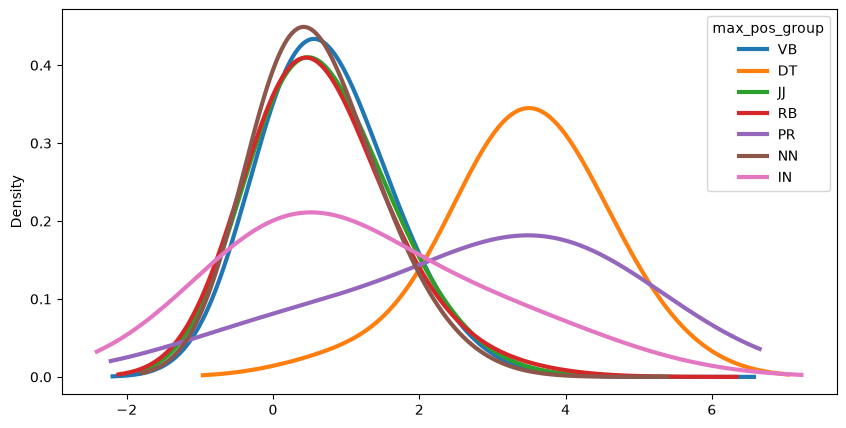

In [64]:
vocab_wide_df.plot.kde(bw_method=1, lw=3, figsize=(10, 5))

plt.show()

**Answers:**

1. DT has the highest peak in the right-hand group
2. IN has the lowest peak in the left-hand group
3. No. While IN (Preposition) includes less frequently used prepositions, which shifts its peak to lower frequency, the core words that IN encompasses are still high-frequency, so the general rule is not called into question.